In [2]:
!pip install ultralytics roboflow


In [3]:
from ultralytics import YOLO
from roboflow import Roboflow
import torch
print("✅ GPU Available:", torch.cuda.is_available())


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
✅ GPU Available: True


In [ ]:
import os

from roboflow import Roboflow

# The API key is read from the environment - never commit it.
#   export ROBOFLOW_API_KEY="your_key_here"
# Get a free key at https://app.roboflow.com/settings/api
api_key = os.environ["ROBOFLOW_API_KEY"]

# Dataset: https://universe.roboflow.com/parsa-karkooti/pcb-wik5v-zonih
rf = Roboflow(api_key=REDACTED_key)
project = rf.workspace("parsa-karkooti").project("pcb-wik5v-zonih")
dataset = project.version(1).download("yolov8")


# Train the YOLOv8 model

In [6]:
model = YOLO("yolov8n.pt")  # lightweight Nano model

model.train(
    data=dataset.location + "/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    device=0
)


Ultralytics 8.3.220 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PCB-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12.0, pr

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 2,  4,  5,  6,  7,  9, 10, 12, 13, 14, 16, 18, 19, 21, 23, 24, 25, 27, 28, 33, 34, 35, 36, 38, 40, 41, 42, 43, 44, 45, 46, 47, 49])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bfc2ce0f4a0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039

# Model evaluation

In [7]:
metrics = model.val()
print(metrics)


Ultralytics 8.3.220 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 3,015,398 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1831.4±682.4 MB/s, size: 67.8 KB)
val: Scanning /content/PCB-1/valid/labels.cache... 128 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 275.6Kit/s 0.0s
val: /content/PCB-1/valid/images/pcb105rec1_jpg.rf.726e2eec09babc744f3e9491b08391c0.jpg: 2 duplicate labels removed
val: /content/PCB-1/valid/images/pcb105rec1_jpg.rf.79ac4876362e37c5d454789c7faf6665.jpg: 2 duplicate labels removed
val: /content/PCB-1/valid/images/pcb122rec1_jpg.rf.3691337ae1276eaeacaa9b16883aa411.jpg: 1 duplicate labels removed
val: /content/PCB-1/valid/images/pcb122rec1_jpg.rf.9a1e85e419007587be67c166ece2b2d0.jpg: 1 duplicate labels removed
val: /content/PCB-1/valid/images/pcb126rec1_jpg.rf.cbe7fbbc2c853cf5d2bd9b6cf56eab8a.jpg: 1 duplicate labels removed
WARNING ⚠️ Box and segment counts should b

# Inference on a few sample images


image 1/123 /content/PCB-1/test/images/ACM-109_Bottom_jpg.rf.992cd63d8fa488dce3f5cafb35486049.jpg: 640x640 6 Capacitors, 2 Connectors, 2 ICs, 1 Pins, 1 Resistor Jumper, 4 Resistor Networks, 22 Unknown Unlabeleds, 8.2ms
image 2/123 /content/PCB-1/test/images/ACM-109_Bottom_jpg.rf.fa7dda9be6455c06d684e8f0cac10e66.jpg: 640x640 11 Capacitors, 2 Connectors, 1 IC, 3 Pinss, 4 Resistor Jumpers, 2 Resistor Networks, 1 Test Point, 16 Unknown Unlabeleds, 8.1ms
image 3/123 /content/PCB-1/test/images/ACM-109_Top_jpg.rf.2c3a9a2e526965cb854e36cf70277c96.jpg: 640x640 7 Capacitors, 5 Capacitor Jumpers, 7 Capacitor Networks, 1 Connector, 11 ICs, 1 Led, 6 Resistor Jumpers, 11 Resistor Networks, 1 Switch, 7.4ms
image 4/123 /content/PCB-1/test/images/ATTIOT_Top_JPG_jpg.rf.eeade80e7d22ba641e8d0b54f896f6c6.jpg: 640x640 2 Buttons, 4 Capacitors, 17 Connectors, 2 Diodes, 1 Electrolytic Capacitor, 3 Fiducials, 10 ICs, 4 Inductors, 3 Resistor Networks, 2 Transistors, 7.4ms
image 5/123 /content/PCB-1/test/images/

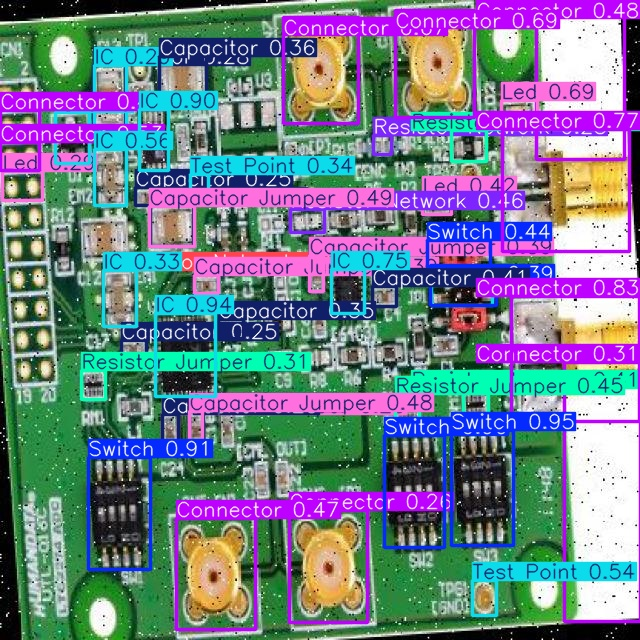

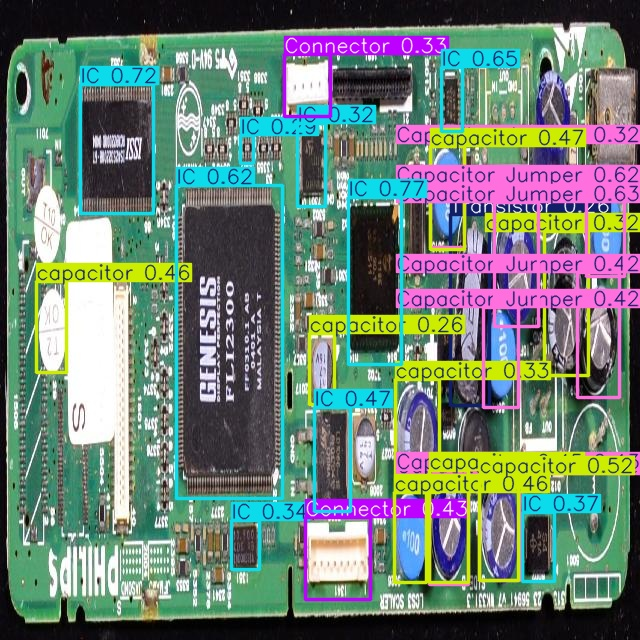

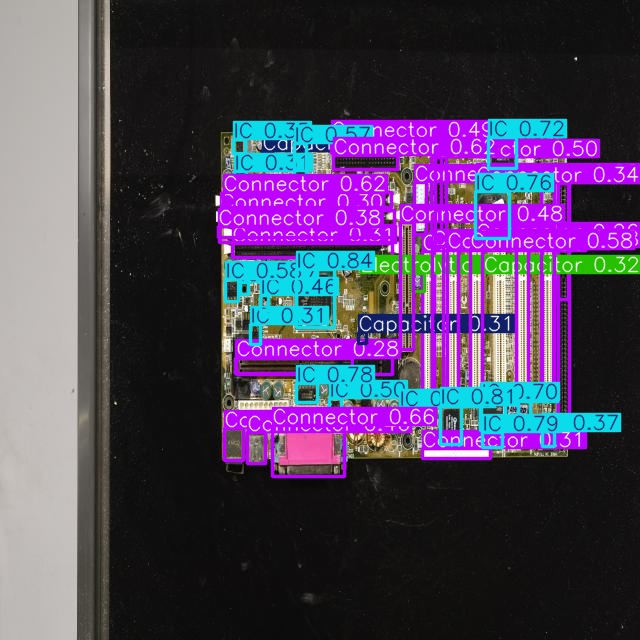

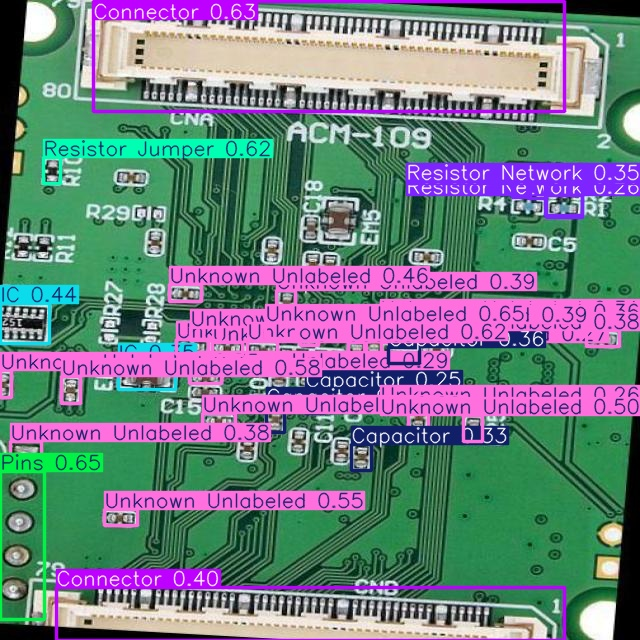

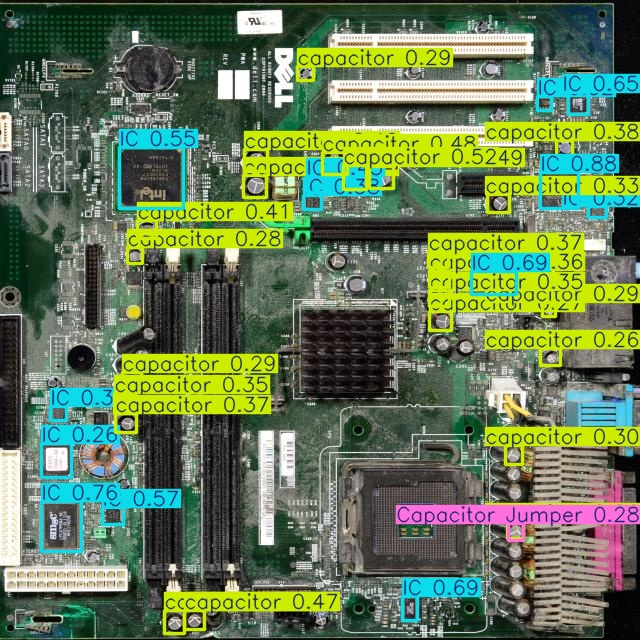

In [8]:
results = model.predict(source=dataset.location + "/test/images", save=True)

import glob
from IPython.display import Image, display

for img_path in glob.glob("runs/detect/predict/*.jpg")[:5]:
    display(Image(filename=img_path))
